# Exploratory data analysis / 数据探索

Memotion sarcasm split as exported for the team (README 3). Everything below is aggregate:
**no dataset image or caption is displayed**, so the executed notebook can be committed
(team rule: never commit dataset content).

所有输出均为汇总统计，不显示任何数据集图片或文字，可以提交到 Git。

Needs `MEMOTION_DATA_DIR` (or the dataset in `data/raw/`). The last section reads the feature
caches in `data/processed/features/` if they are there.

In [1]:
import os, sys
from pathlib import Path

ROOT = Path.cwd().resolve()
while not (ROOT / "configs" / "train").is_dir():      # run from notebooks/ or the repo root
    ROOT = ROOT.parent
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
print("dataset from", "MEMOTION_DATA_DIR" if os.environ.get("MEMOTION_DATA_DIR") else "data/raw/ (default)")

dataset from MEMOTION_DATA_DIR


## 1. Split sizes and labels / 划分与标签

In [2]:
import pandas as pd
from src.data.dataset import EXPECTED_SPLIT_SIZES, NO_TEXT, SPLITS, load_split

frames = {s: load_split(s) for s in SPLITS}
summary = pd.DataFrame({
    s: {"rows": len(f), "expected": EXPECTED_SPLIT_SIZES[s],
        "not_sarcastic (0)": int((f.sarcasm_binary == 0).sum()),
        "sarcastic (1)": int((f.sarcasm_binary == 1).sum()),
        "share of class 1": round(float(f.sarcasm_binary.mean()), 3)}
    for s, f in frames.items()}).T
summary

,rows,expected,not_sarcastic (0),sarcastic (1),share of class 1
train,5593.0,5593.0,1226.0,4367.0,0.781
validation,699.0,699.0,161.0,538.0,0.770
test,700.0,700.0,157.0,543.0,0.776


In [3]:
# 4-class sarcasm label -> binary target (README 3.3)
everything = pd.concat(frames.values(), ignore_index=True)
pd.crosstab(everything.sarcasm, everything.split)

split,test,train,validation
sarcasm,,,
general,343,2797,367
not_sarcastic,157,1226,161
twisted_meaning,151,1262,134
very_twisted,49,308,37


In [4]:
train = frames["train"]
n, n0, n1 = len(train), int((train.sarcasm_binary == 0).sum()), int((train.sarcasm_binary == 1).sum())
print(f"class weights from TRAIN only (README 5.2): w0 = {n / (2 * n0):.3f}, w1 = {n / (2 * n1):.3f}")
from src.evaluation.metrics import majority_baseline
print(f"majority baseline on validation: Macro-F1 = {majority_baseline(frames['validation'].sarcasm_binary)['macro_f1']:.4f}")

class weights from TRAIN only (README 5.2): w0 = 2.281, w1 = 0.640


majority baseline on validation: Macro-F1 = 0.4349


## 2. Captions / 文字

In [5]:
import matplotlib.pyplot as plt
import numpy as np

words = {s: f.text_input.where(f.text_input != NO_TEXT, "").str.split().str.len() for s, f in frames.items()}
pd.DataFrame({s: {"[NO_TEXT]": int((f.text_input == NO_TEXT).sum()),
                  "words mean": round(float(w.mean()), 1), "words median": float(w.median()),
                  "words p95": float(w.quantile(0.95)), "words max": int(w.max())}
              for (s, f), w in zip(frames.items(), words.values())}).T

,[NO_TEXT],words mean,words median,words p95,words max
train,1.0,14.7,13.0,31.0,189.0
validation,0.0,14.6,13.0,30.0,73.0
test,3.0,14.7,13.0,32.0,94.0


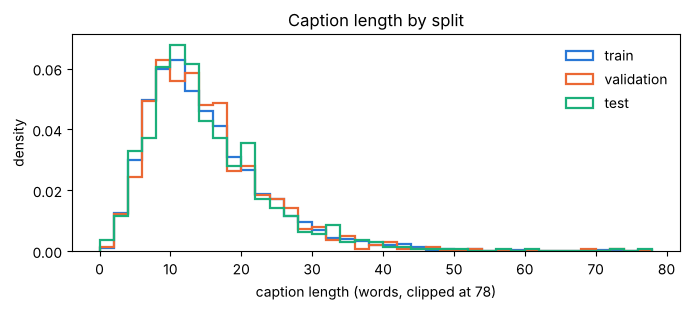

In [6]:
fig, ax = plt.subplots(figsize=(7, 3.2))
bins = np.arange(0, 80, 2)
for s, color in zip(SPLITS, ("#2a78d6", "#eb6834", "#1baf7a")):
    ax.hist(words[s].clip(upper=78), bins=bins, density=True, histtype="step", lw=1.6, color=color, label=s)
ax.set_xlabel("caption length (words, clipped at 78)"); ax.set_ylabel("density")
ax.set_title("Caption length by split"); ax.legend(frameon=False)
fig.tight_layout()

In [7]:
# caption length vs label (train): is length alone informative?
t = train.assign(words=words["train"])
t.groupby("sarcasm_binary").words.describe()[["count", "mean", "50%", "75%", "max"]]

,count,mean,50%,75%,max
sarcasm_binary,,,,,
0,1226.0,14.677814,13.0,19.0,65.0
1,4367.0,14.657660,13.0,19.0,189.0


In [8]:
# DistilBERT token lengths, recorded by the text feature extraction (meta.json)
import json
meta_path = Path("data/processed/features/distilbert_first_token/meta.json")
if meta_path.exists():
    meta = json.loads(meta_path.read_text())
    display(pd.DataFrame(meta["splits"]).T[["n", "no_text", "tokens_mean", "tokens_median",
                                           "tokens_max", "truncated_at_max_length"]])
    print("max_length =", meta["max_length"], "| tokenizer:", meta["tokenizer"])
else:
    print("no text cache yet: python -m src.features.feature_engineering text")

,n,no_text,tokens_mean,tokens_median,tokens_max,truncated_at_max_length
train,5593,1,22.98,20.0,261,4
validation,699,0,23.04,21.0,96,0
test,700,3,23.2,20.0,135,1


max_length = 128 | tokenizer: BertTokenizer


## 3. Images / 图片 (file headers only)

In [9]:
from PIL import Image

rows = []
for s, f in frames.items():
    for path in f.image_abspath:
        with Image.open(path) as im:                 # reads the header, not the pixels
            rows.append({"split": s, "mode": im.mode, "format": im.format,
                         "width": im.width, "height": im.height})
images = pd.DataFrame(rows)
images["aspect (h/w)"] = images.height / images.width
pd.crosstab(images["mode"], images.split)

split,test,train,validation
mode,,,
CMYK,0,2,0
L,6,22,3
P,130,997,121
RGB,537,4378,553
RGBA,27,194,22


In [10]:
images.groupby("split")[["width", "height", "aspect (h/w)"]].describe().T.round(2)

split                  test    train  validation
width        count   700.00  5593.00      699.00
             mean    579.50   585.77      605.02
             std     236.52   258.13      265.47
             min     160.00   100.00      200.00
             25%     480.00   480.00      480.00
             50%     500.00   501.00      528.00
             75%     640.00   640.00      674.00
             max    2581.00  4961.00     2000.00
height       count   700.00  5593.00      699.00
             mean    546.84   545.27      556.08
             std     250.35   251.94      234.16
             min     168.00   123.00      150.00
             25%     393.00   390.00      400.00
             50%     500.00   500.00      512.00
             75%     650.00   646.00      675.00
             max    2248.00  5553.00     2533.00
aspect (h/w) count   700.00  5593.00      699.00
             mean      0.97     0.96        0.96
             std       0.31     0.30        0.29
             min       0.41     0.23        0.28
             25%       0.75     0.74        0.75
             50%       0.98     0.98        1.00
             75%       1.12     1.13        1.13
             max       2.99     3.00        1.92

share with h/w > 1.5 (top/bottom text likely cropped): 5.2%


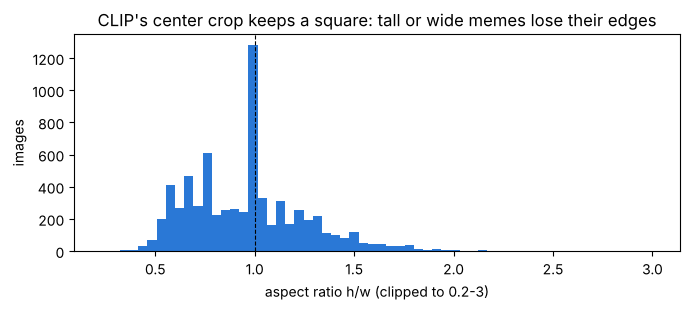

In [11]:
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.hist(images["aspect (h/w)"].clip(0.2, 3), bins=60, color="#2a78d6")
ax.axvline(1.0, color="black", lw=0.8, ls="--")
ax.set_xlabel("aspect ratio h/w (clipped to 0.2-3)"); ax.set_ylabel("images")
ax.set_title("CLIP's center crop keeps a square: tall or wide memes lose their edges")
fig.tight_layout()
print(f"share with h/w > 1.5 (top/bottom text likely cropped): {(images['aspect (h/w)'] > 1.5).mean():.1%}")

## 4. Other annotations vs sarcasm / 其他标注与讽刺 (train)

In [12]:
for column in ("humor", "offensive", "motivational", "sentiment"):
    display(pd.crosstab(train[column], train.sarcasm_binary, normalize="index").round(3)
              .rename(columns={0: "P(not sarcastic)", 1: "P(sarcastic)"}))

sarcasm_binary,P(not sarcastic),P(sarcastic)
humor,,
funny,0.188,0.812
hilarious,0.193,0.807
not_funny,0.387,0.613
very_funny,0.136,0.864


sarcasm_binary,P(not sarcastic),P(sarcastic)
offensive,,
hateful_offensive,0.165,0.835
not_offensive,0.436,0.564
slight,0.084,0.916
very_offensive,0.065,0.935


sarcasm_binary,P(not sarcastic),P(sarcastic)
motivational,,
motivational,0.138,0.862
not_motivational,0.263,0.737


sarcasm_binary,P(not sarcastic),P(sarcastic)
sentiment,,
negative,0.214,0.786
neutral,0.276,0.724
positive,0.197,0.803
very_negative,0.278,0.722
very_positive,0.158,0.842


## 5. Cached encoder features / 缓存特征

In [13]:
import torch
import torch.nn.functional as F

caches = {"DistilBERT [CLS]": "distilbert_first_token", "DistilBERT mean": "distilbert_mean_pooling",
          "CLIP (image group, CUDA)": "20261006_code_fixes_validation_v2",
          "CLIP (CPU)": "clip_vitb32_pooler_cpu"}
stats = {}
for name, folder in caches.items():
    path = Path("data/processed/features") / folder / "train.pt"
    if not path.exists():
        continue
    x = torch.load(path, weights_only=True)["features"].double()
    xn = F.normalize(x, dim=-1)
    mean_cos = ((xn.sum(0).norm() ** 2 - len(xn)) / (len(xn) * (len(xn) - 1))).item()
    stats[name] = {"rows": len(x), "dim": x.shape[1], "norm mean": x.norm(dim=1).mean().item(),
                   "mean pairwise cosine": mean_cos}
pd.DataFrame(stats).T.round(4) if stats else "no caches in data/processed/features/"

,rows,dim,norm mean,mean pairwise cosine
DistilBERT [CLS],5593.0,768.0,12.0195,0.8971
DistilBERT mean,5593.0,768.0,7.8636,0.7264
"CLIP (image group, CUDA)",5593.0,768.0,26.1461,0.2684
CLIP (CPU),5593.0,768.0,26.1465,0.2684


High mean pairwise cosine = anisotropic features (all vectors point in similar directions),
typical of a frozen `[CLS]` state; this is one reason the text-only head is weak
(results report §8). / 平均余弦越高，特征越各向异性，冻结的 `[CLS]` 尤其明显。

In [14]:
a, b = (Path("data/processed/features") / d / "validation.pt"
        for d in ("20261006_code_fixes_validation_v2", "clip_vitb32_pooler_cpu"))
if a.exists() and b.exists():
    xa, xb = (torch.load(p, weights_only=True) for p in (a, b))
    assert xa["sample_id"] == xb["sample_id"]
    cos = F.cosine_similarity(xa["features"].double(), xb["features"].double())
    print(f"CUDA (TF32) vs CPU CLIP features, validation: mean cosine {cos.mean():.6f}, "
          f"min {cos.min():.4f}, below 0.999: {(cos < 0.999).sum().item()} of {len(cos)}")

CUDA (TF32) vs CPU CLIP features, validation: mean cosine 0.999967, min 0.9854, below 0.999: 3 of 699
